# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

Actividad de Semana 3

### **Rotación de Personal - IBM**

* **Nombre:** Mariana Pérez Sánchez

* **matrícula:** A01099907

------------

* #### **En esta actividad puedes apoyarte en uno o varios Modelos de Lenguaje de Gran Tamaño, LLM por sus siglas en inglés (Large Language Model). Indica claramente cuál o cuáles utilizaste.**

* #### **La siguiente actividad se basa en los datos del archivo "WA_Fn-UseC_-HR-Employee-Attrition.csv" que se encuentra en la siguiente liga de Kaggle, llamada "IBM HR Analytics Employee Attrition & Performance".**

* #### **Los datos los proporcionó IBM y aunque comentaron que por cuestiones de privacidad los datos son sintéticos, los generaron con base a su experiencia. Estos datos en general son referencia cuando se habla en Estadística o Aprendizaje Automático sobre el tema de rotación de personal.**

**El archivo contiene 1470 registros:**

https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset


# **Ejercicio 1:**

#### **Incluye una breve introducción sobre lo que se entiende por el problema de rotación de personal en las organizaciones (employee attrition problem).**

++++++++ Inicia la sección de agregar texto: ++++++++++++
Rotación de personal: movimiento constante de colaboradores dentro de una organización, cuando las personas permanecen poco tiempo en sus puestos y deben ser reemplazadas continuamente.
Esto puede ser un probema cuando el colaborador no permanece el tiempo suficiente para completar su curva de aprendizaje, desarrollar plenamente las competencias necesarias y alcanzar los resultados esperados. Se puede entrar en un ciclo constante de contratación, integración y capacitación de nuevos colaboradores, sin llegar a obtener completamente el valor esperado de la posición.



++++++++ Termina la sección de agregar texto. +++++++++++

In [1]:
# Agrega aquí todas las librerías adicionales o paquetes que consideres necesarias:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate

from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report



* #### **Descarga el archivo de datos de la página de Kaggle.**

* #### **Cargamos el archivo como un DataFrame de Pandas y hacemos uso del método “describe” con el argumento include= “all” para desplegar información de todas las variables, numéricas y categóricas.**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
path = "/content/drive/MyDrive/Maestría/Inteligencia artificial y aprendizaje automático/Actividad semana 3/WA_Fn-UseC_-HR-Employee-Attrition.csv"
data = pd.read_csv(path)

print("Tamaño del DataFrame:", data.shape)
data.describe(include = 'all').T


Tamaño del DataFrame: (1470, 35)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


# **Ejercicio 2:**

**a) Realiza los análisis descriptivos y/o gráficos que creas adecuados para identificar 4 factores que se deben eliminar desde un inicio.**

**Al nuevo DataFrame sin las variables indicadas, llamarlo df.**



In [ ]:
# a) Incluye a continuación el código y celdas que creas adecuados para responder a la pregunta.

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++


None


# ++++++++++ Termina sección para agregar código +++++++++++++++++++++++++++


# Verifiquemos de qué tamaño queda el nuevo DataFrame:
# print("Tamaño del nuevo DataFrame:", df.shape)

In [8]:
data.dtypes.value_counts()

,count
int64,26
object,9


In [9]:
data.describe(include = ['number']).T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [10]:
data.describe(include = ['object']).T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [11]:
data.nunique().sort_values()

,0
EmployeeCount,1
Over18,1
StandardHours,1
Attrition,2
OverTime,2
PerformanceRating,2
Gender,2
BusinessTravel,3
Department,3
MaritalStatus,3


In [12]:
variables_eliminar = ['EmployeeNumber', 'Over18', 'StandardHours', 'EmployeeCount']
df = data.drop(columns=variables_eliminar)
print("Tamaño del nuevo DataFrame:", df.shape)

Tamaño del nuevo DataFrame: (1470, 31)


**b) Con base a tu análisis anterior, indica cuáles fueron estas 4 variables y la justificación de por qué se pueden eliminar.**

Tras analizar la función `describe` de "data", realicé un conteo de variables numéricas y categóricas para poder aplicar la función `describe` específica y aplicable al tipo de variable.
Una vez que se aplicó `describe` para cada tipo de variable, apliqué la función `nunique` para entender si alguna de las variables representaba algún ID que no fuera representativo para el análisis.

Las 4 variables que se eliminaron fueron:


*   **EmployeeNumber:** Encontramos 1470 valores únicos, misma cantidad de registros que el dataframe, por lo que se entiende que es un valor único de cada empleado y no representaría valor para el análisis.

*   **Over18:** en el análisis podemos observar que el valor top es "y" entendiendo esto como un "yes" con una frecuencia de 1470 igual que el número de registros del dataframe, por lo que podemos considerar esta variable como una constante.

*   **StandardHours:** podemos observar que no hay ninguna variación en el valor de horas, el promedio y cuartiles tienen el mismo valor y la desviación estandar es de 0. También podemos asumir que la variable es una constante.

*  **EmployeeCount:** en esta variable también podemos observar que no hay variación en los valores de promedio y cuartiles. Podemos asumir que es un índice de conteo y también la podemos asumir con una constante.





# **Ejercicio 3:**

#### **Una vez eliminadas las variables no deseadas, clasifiquemos las restantes como se indica a continuación y en base a la información dada en la plataforma de Kaggle.**

#### **El número entre corcheas indica el número de variables de dicho tipo y el  número entre paréntesis redondos indica el número de niveles.**

* **Variables numéricas [14]:**

   * NumCompaniesWorked

   * TrainingTimesLastYear

   * Age

   * DailyRate

   * DistanceFromHome

   * HourlyRate

   * MonthlyIncome

   * MonthlyRate

   * PercentSalaryHike

   * TotalWorkingYears

   * YearsAtCompany

   * YearsInCurrentRole

   * YearsSinceLastPromotion

   * YearsWithCurrManager

* **Variables ordinales [9]:**

   * Education (5)

   * EnvironmentSatisfaction (4)

   * JobInvolvement (4)

   * JobLevel (5)

   * JobSatisfaction (4)

   * PerformanceRating (2)

   * RelationshipSatisfaction (4)

   * StockOptionLevel (4)

   * WorkLifeBalance (4)

* **Variables binarias [3]:**

   * Attrition (variable de salida)

   * Gender

   * OverTime

* **Variables nominales [5]:**

   * BusinessTravel (3)

   * Department (3)

   * EducationField (6)

   * JobRole (9)

   * MaritalStatus (3)

**Indpendientemente de los factores que al final el modelo identifique como los factores más importantes a considerar en este problema de rotación de personal ¿qué preocupaciones éticas o legales podrían generarse, si algunos de estos factores más importantes a considerar para tomar decisiones sobre los empleados fueran la edad (Age), el género (Gender) o el estado civil (Marital Status)?**


Respuesta: Considero que estas variables específicas podrían llegar a categorizarse o entenderse como cierta discriminación si se utilizan como factores para la toma de decisiones. Podríamos poner como ejemplo que el modelo identifica que hay mayor rotación en las personas mayores a 50 años por lo que la decisión de la compañía se podría ver sesgada a no contratar a gente debido a su edad.
Situaciones similares se pueden presentar en "género" y "estado civil". Es decir, identificar una mayor rotación de mujeres o personas solteras no deberpia convertirse en un criterio para decidir contrataciones, promociones o incluso despidos.
Desde la perspectiva ética, esto podría generar sesgos y discriminación ya que una persona estaría siendo evaluada por características personales y no por su desempeño laborar, actitudes y aptitudes. Aquí podríamos entrar en temas sobre legislaciones contra la discriminación que terminen siendo un problema legal.


# **Ejercicio 4:**

**a) Aunque este problema como está planteado es un problema de clasificación binaria, ¿qué otros enfoques analíticos podrían plantearse y modelarse a partir de este problema? Menciona al menos dos más.**



* Podríamos usar regresión para poder obtener el ingreso salarial y con qué variables se encuentra más relacionado.
* También podríamos usar clustering para identificar perfiles de empleados, y encontrar segmentos dentro de la compañía.

### **Para esta actividad usaremos una partición en Train, Val y Test, con los porcentajes que se indican a continuación.**

In [13]:
print("Dimensiones y Porcentajes de la partición Train+Validation+Test generada:")
print("-"*75)

X = df.drop(columns='Attrition')
y = df[['Attrition']]

Xtrain, Xtv, ytrain, ytv = train_test_split(X, y, train_size=0.70, stratify=y, random_state=17)
Xval, Xtest, yval, ytest = train_test_split(Xtv, ytv, test_size=0.5, stratify=ytv, random_state=17)

print("Variables de entrada Train, Validation, Test:")
print(Xtrain.shape, '%.1f%%' % (100.*Xtrain.shape[0]/X.shape[0]))
print(Xval.shape, '%.1f%%' % (100.*Xval.shape[0]/X.shape[0])),
print(Xtest.shape, '%.1f%%' % (100.*Xtest.shape[0]/X.shape[0]))

print("\nVariables de salida Train, Validation, Test:")
print(ytrain.shape)
print(yval.shape)
print(ytest.shape)

Dimensiones y Porcentajes de la partición Train+Validation+Test generada:
---------------------------------------------------------------------------
Variables de entrada Train, Validation, Test:
(1029, 30) 70.0%
(220, 30) 15.0%
(221, 30) 15.0%

Variables de salida Train, Validation, Test:
(1029, 1)
(220, 1)
(221, 1)


# **Ejercicio 5:**


**a) Aplica la transformación LabelEncoder() de Sklearn a la variable“Attrition”, tomando en cuenta los siguientes puntos:**

* **Las nuevas variables deberán llamarse ahora: ytrainT, yvalT, ytestT.**

* **Al aplicar la transformación LabelEncoder deberás evitar el filtrado de información (data-leakage).**


In [ ]:
# a)
# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++


None


# +++++++++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# print('Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):\n', ytrainT['Attrition'].value_counts() / ytrainT.shape[0])

In [17]:
label_encoder = LabelEncoder()
ytrainT = label_encoder.fit_transform(ytrain['Attrition'])
yvalT = label_encoder.transform(yval['Attrition'])
ytestT = label_encoder.transform(ytest['Attrition'])

# Convertimos a una Serie de Pandas para poder usar .value_counts() - ayuda de Gemini
print('Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):\n', pd.Series(ytrainT).value_counts() / ytrainT.shape[0])

Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):
 0    0.838678
1    0.161322
Name: count, dtype: float64


#### Además, responde las siguientes preguntas:

**b) Con base a la documentación actual de Sklearn, ¿a qué tipo de variables se recomienda aplicar la transformación LabelEncoder?**
A las variables categóricas, para codificar las etiquetas de la variable de salida, transformando categorías en valores numéricos.

**c) Con base al contexto del problema, ¿qué significan los valores 0 (NO) y 1 (YES) de la variable de salida Attrition?**
* 0 significa que ese empleado específico no tiene un attrition, es decir que sigue en la compañía.
* 1 significa que eese empleado específico dejó la compañía.

Existe un 16.13% de vacantes/posiciones a cubrir.

**d) Con base a la información obtenida y considerando la métrica de la exactitud (accuracy) ¿cuál será el valor del umbral del modelo base o ingenuo (baseline, naive) a superar para evitar tener un modelo subentrenado una vez que empecemos a generarlos?**

El valor sería el 83.86% que estamos obteniendo en LabelEncoder. Ese es el valor que los demás modelos deberian superar.

**e) Indica si el desbalanceo de clases obtenido puede ya considerarse como un problema, y de considerarlo así, qué otra métrica o métricas podrían ser más adecuadas que la exactitud (accuracy).**

Sí podría considerarse un problema ya que hay un desbalanceo importante en cada una de las clases: 83.86% vs 16.13%.
Se podrían usar recall, f1-score para entender el desempeño que tiene el modelo o precision para identificar qué porcentaje de acierto hay cuando el modelo predice que el dato pertenece a la clase positiva.



++++++++ Inicia la sección de agregar texto: ++++++++++++

b) None   

c) None  

d) None

e) None

++++++++ Termina la sección de agregar texto. +++++++++++

# **Ejercicio 6:**


#### **Incluye a continuación un análisis gáfico y descriptivo que consideres adecuado.**

  * **a) El análisis debe ser suficiente para que te ayude a tomar las decisiones sobre qué transformaciones aplicar a cada variable antes de entrenar los modelos.**

  * **b) Además, para obtener mayor información sobre la relación entre variables, incluye un gráfico de barras de frecuencias ordenadas de mayor a menor, de la variable "Age", únicamente para los casos de empleados que ya no están en la compañía (Attrition=Yes).**

  * **c) Incluye también un gráfico de barras ordenado de la relación entre Education y Attrition=Yes. Muestra además en el gráfico las etiquetas asociadas a Education en lugar de los números, como se indica en la página de Kaggle.**

  * **d) [Opcional] Incluye algún otro gráfico o gráficos que consideres aporta información para el análisis y entendimiento del problema. Si no encuentras algún otro gráfico de interés, deberas indicarlo.**

  * **e) Para la empresa de IBM ¿qué es más costoso? ¿clasificar erróneamente a un empleado que sí renunciará, o por el contrario, generar una falsa alarma?**


In [ ]:

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# Incluye en esta sección todas las celdas que consideres necesarias.

# a) Análsis y gráficos

None


# b) Gráfico age-attrition[yes]

None

# c) Gráfico education-attrition[yes]

None

# d) [gráfico opcional]

None


# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++



In [27]:
num_cols = [
    'NumCompaniesWorked',
    'TrainingTimesLastYear',
    'Age',
    'DailyRate',
    'DistanceFromHome',
    'HourlyRate',
    'MonthlyIncome',
    'MonthlyRate',
    'PercentSalaryHike',
    'TotalWorkingYears',
    'YearsAtCompany',
    'YearsInCurrentRole',
    'YearsSinceLastPromotion',
    'YearsWithCurrManager'
]

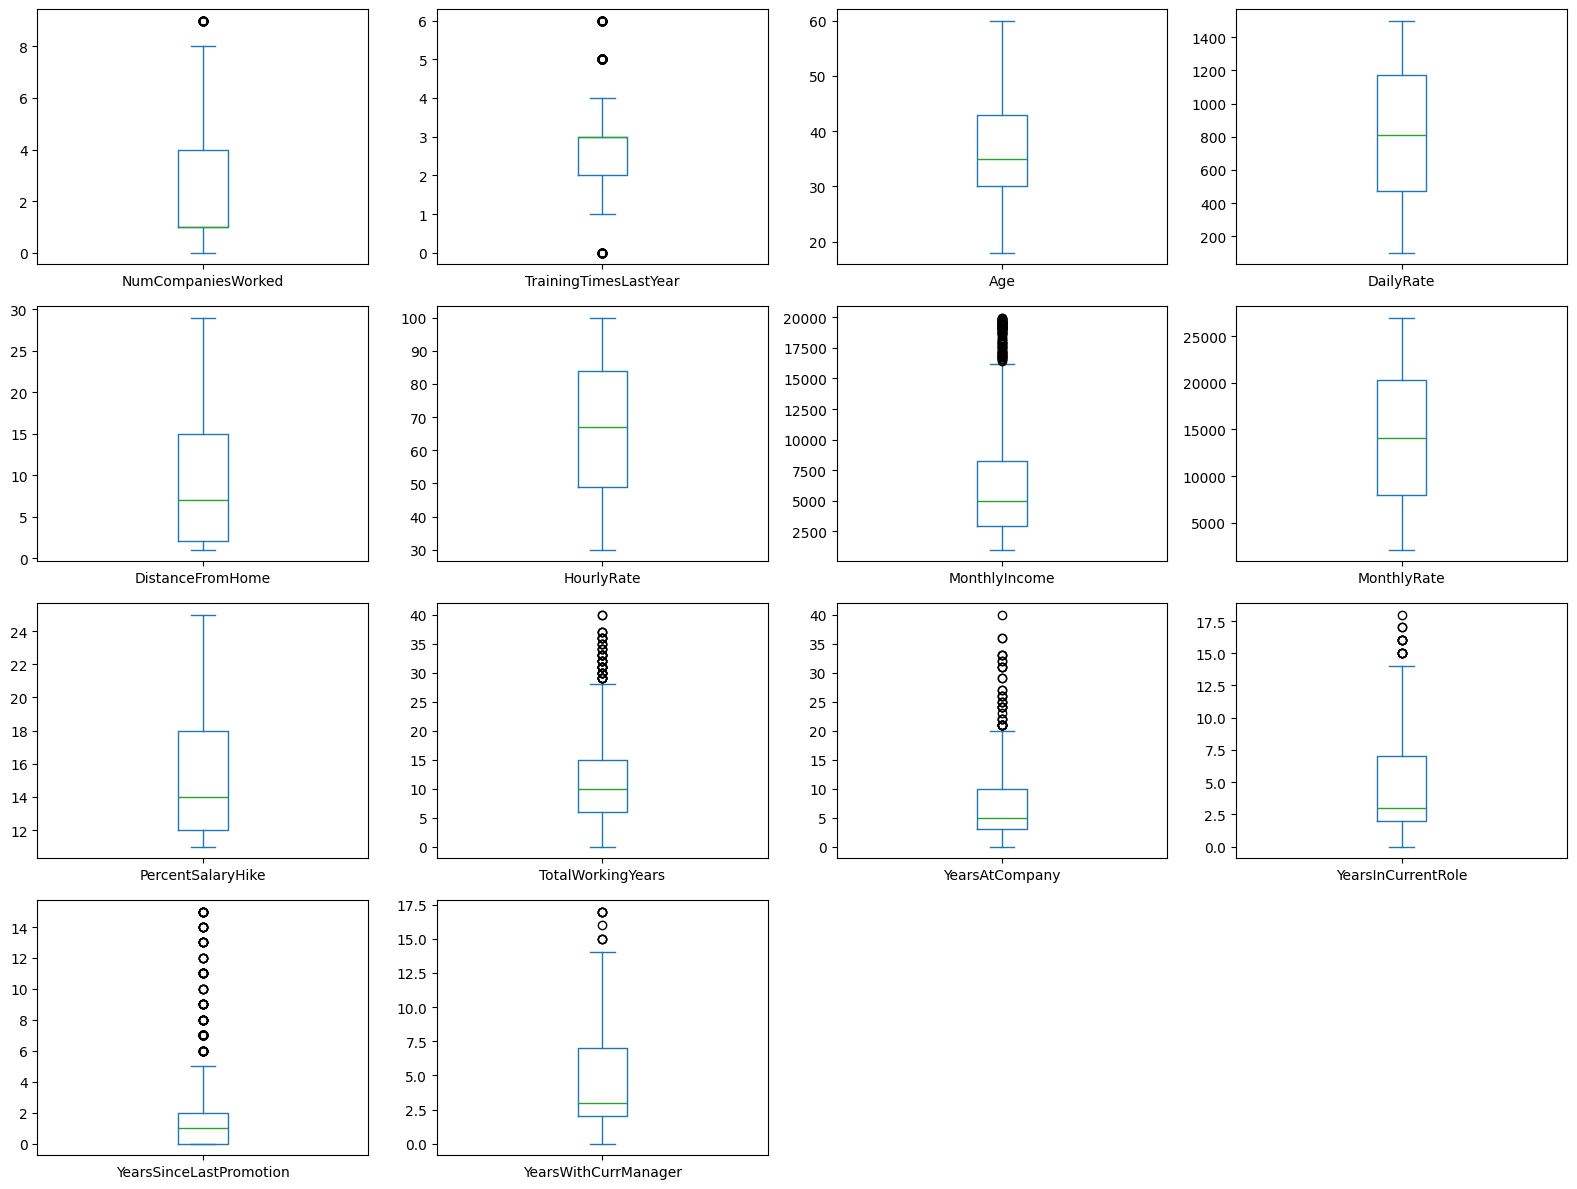

In [28]:
Xtrain[num_cols].plot(kind='box', figsize=(16,12), subplots=True, layout=(4,4), sharex=False, sharey=False)
plt.tight_layout()
plt.show()

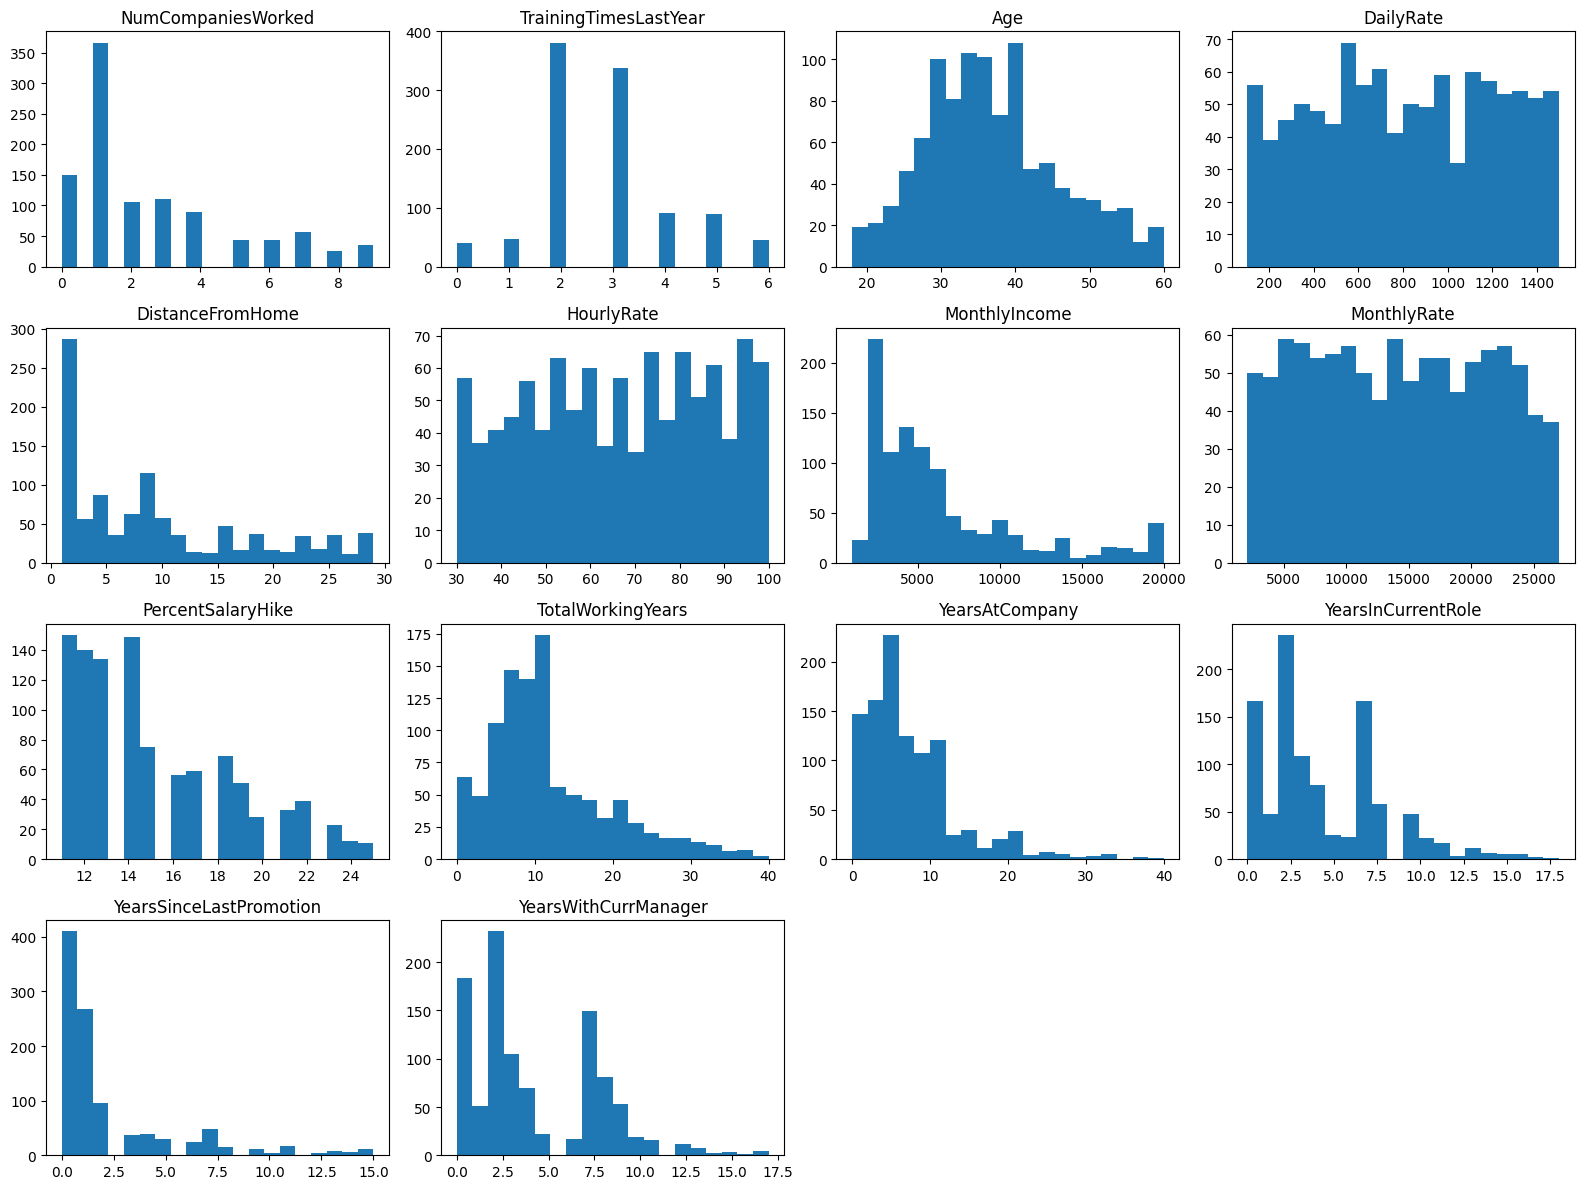

In [29]:
fig, axes = plt.subplots(4, 4, figsize=(16,12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
  axes[i].hist(Xtrain[col], bins=20)
  axes[i].set_title(col)

for i in range(i+1, len(axes)):
  axes[i].set_visible(False)

plt.tight_layout()
plt.show()

**a) Apartir de los diagramas de caja y de los histogramas se observan diferencias importantes tanto en la escala como en la distribución de las variables numércias. Variables como `Age`, `DailyRate`, `HourlyRate` & `MonthlyRate` presentan distribuciones relativamente simétricas o uniformes y no muestran presencia importante de valores atípicos.
A su vez, tenemos variables como `MonthlyIncome`, `TotalWorkingYears`, `YearsatCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion` y `YearsWithCurrManager` que presentan una asimetría positiva, con una mayor concentración de valores bajos y colas hacia valores altos.
Se podría considerar aplicar Yeo-Johnson debido a los valores en 0.**

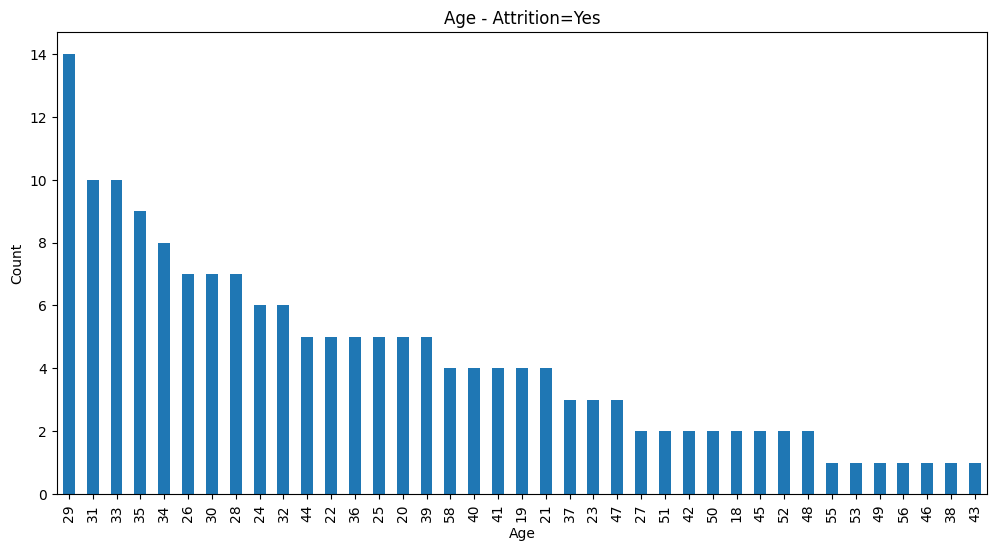

In [35]:
age_attrition_yes = Xtrain.loc[ytrain['Attrition'] == 'Yes', 'Age'].value_counts().sort_values(ascending=False)
age_attrition_yes

plt.figure(figsize=(12,6))
age_attrition_yes.plot(kind='bar')
plt.title('Age - Attrition=Yes')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

In [34]:
ytrain.head()

,Attrition
565,No
857,Yes
1192,No
1305,No
1144,No


**B) Aunque podemos visualizar que hay variación en las edades, encontramos que la edad con mayor frecuencia de attrition es 29 años seguido de 31, 33, 35 y 34. Podríamos intuir que las mayores frecuencias se encuentran en empleados jóvenes. **

In [36]:
Xtrain['Education'].unique()

array([1, 4, 3, 5, 2])

In [37]:
education_labels = {
    1: 'Below College',
    2: 'College',
    3: 'Bachelor',
    4: 'Master',
    5: 'Doctor'
}

In [41]:
education_attrition_yes = Xtrain.loc[ytrain['Attrition'] == 'Yes', 'Education'].map(education_labels).value_counts().sort_values(ascending=False)
education_attrition_yes

,count
Education,
Bachelor,64
Master,41
College,31
Below College,26
Doctor,4


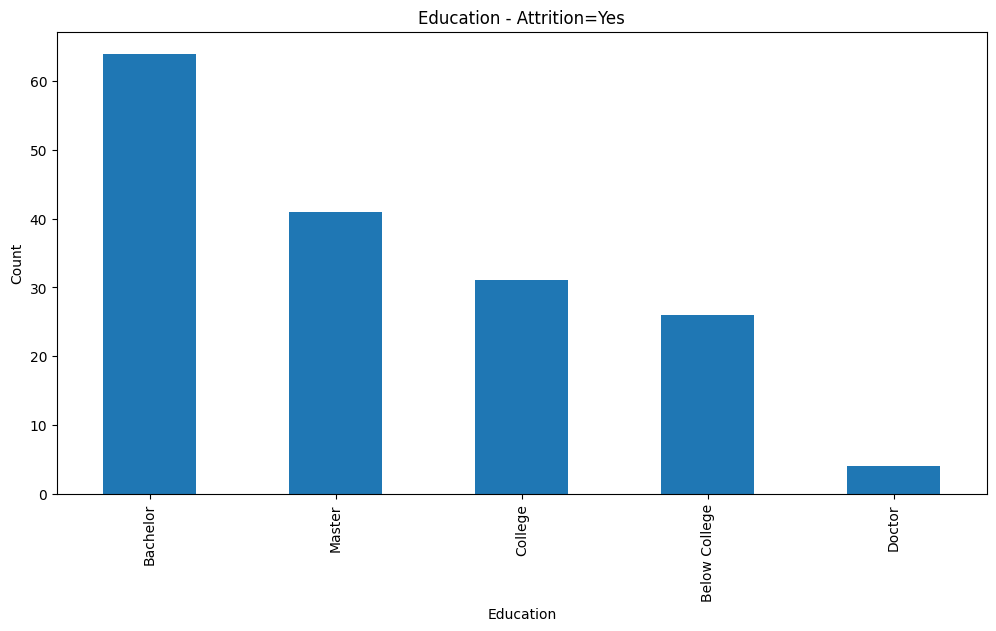

In [42]:
plt.figure(figsize=(12,6))
education_attrition_yes.plot(kind='bar')
plt.title('Education - Attrition=Yes')
plt.xlabel('Education')
plt.ylabel('Count')
plt.show()

**c) Se observa que la mayor frecuencia está en "Bachelor", seguida por "Master" y "College". Sin embargo no se identifica alguna tendencia que nos sugiera que a mayor/menor escolaridad hay mayor/menor attrition.**

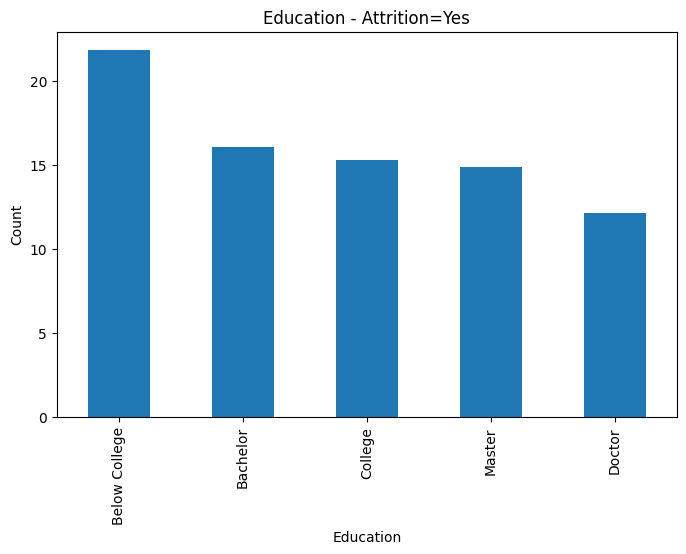

In [43]:
education_rate = (
    pd.crosstab(
        Xtrain['Education'],
        ytrain['Attrition'],
        normalize='index'
    ) ['Yes']* 100
    )
education_rate.index=education_rate.index.map(education_labels)
education_rate.sort_values(ascending=False).plot(kind='bar', figsize=(8,5))
plt.title('Education - Attrition=Yes')
plt.xlabel('Education')
plt.ylabel('Count')
plt.show()

**d) se realiza un análisis del rate de "Educcation" para entender si alguna escolaridad representa mayor attrition, sin embargo observamos que los rates son bastante parejos. Por lo tanto no se observa una relación clara entre mayor/menor nivel educativo.**

**e) ¿Qué es más costoso, los Falsos Negativos o los Falsos Positivos?**

A mi me parece que es mas costoso un Falso Negativo, es decir clasificar erróneamente a un empleado que sí va a renunciar.
El objetivo del análisis y de la empresa es detectar patrones de empleados que pueden renunciar para evitarlo.

# **Ejercicio 7:**

#### **Utiliza las clases Pipeline y ColumnTransformer de Sklearn para definir las transformaciones que deberás aplicar a cada variable y de acuerdo a su tipo considerado previamente.**



In [44]:
# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++


# NUMÉRICAS:
numericas_pipeline = Pipeline([('yeo_johnson', PowerTransformer(method='yeo-johnson'))])
numericas_pipeline_nombres = ['NumCompaniesWorked',
    'TrainingTimesLastYear',
    'Age',
    'DailyRate',
    'DistanceFromHome',
    'HourlyRate',
    'MonthlyIncome',
    'MonthlyRate',
    'PercentSalaryHike',
    'TotalWorkingYears',
    'YearsAtCompany',
    'YearsInCurrentRole',
    'YearsSinceLastPromotion',
    'YearsWithCurrManager']

# ORDINALES:
catOrd_pipeline = Pipeline([('ordinal', 'passthrough')])
catOrd_pipeline_nombres = ['Education',
    'EnvironmentSatisfaction',
    'JobInvolvement',
    'JobLevel',
    'JobSatisfaction',
    'PerformanceRating',
    'RelationshipSatisfaction',
    'StockOptionLevel',
    'WorkLifeBalance']

# BINARIAS:
catBin_pipeline = Pipeline([('binary', OrdinalEncoder())] )
catBin_pipeline_nombres = ['Gender',
    'OverTime']

# NOMINALES:
catNom_pipeline = Pipeline( [('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))] )
catNom_pipeline_nombres = ['BusinessTravel',
    'Department',
    'EducationField',
    'JobRole',
    'MaritalStatus']



columnasTransformer = ColumnTransformer([
    ('numericas', numericas_pipeline, numericas_pipeline_nombres),
    ('ordinales', catOrd_pipeline, catOrd_pipeline_nombres),
    ('binarias', catBin_pipeline, catBin_pipeline_nombres),
    ('nominales', catNom_pipeline, catNom_pipeline_nombres)
] )



# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++

* #### **Vamos a utilizar validación cruzada, por lo que decidimos para esta actividad reagrupar los conjuntos de entrenamiento y validación en un solo DataFrame.**

* #### **Al resultado obtenido los llamaremos Xtv y ytv.**


In [46]:
Xtv = pd.concat([Xtrain, Xval], axis=0)
ytv = pd.concat([
    pd.Series(ytrainT),
    pd.Series(yvalT)
], axis=0)


print("Dimensión del conjunto Train+Val:")
print(Xtv.shape)
print(ytv.shape)

Dimensión del conjunto Train+Val:
(1249, 30)
(1249,)


# **Ejercicio 8:**

#### **Entrenamiento y ajuste de hiperparámetros**

#### **a) Busca los mejores hiperparámetros para cada modelo, de manera que no estén subentrenados con respecto a la métrica de la exactitud (accuracy).**

#### **b) Incluye tus comentarios sobre el resultado obtenido.**



#### **NOTA-1: En dado caso, cuando mucho uno de los modelos podría quedar subentrenado.**

#### **NOTA-2: Por el momento estamos usando la métrica de la exactitud (accuracy). El objetivo de esta actividad es que sepas entrenar modelos sin que resulten subentrenados o sobreentrenados, independientemente de la métrica a considerar. En próximas semanas seguiremos con el estudio de las otras métricas para abordar de mejor manera los problemas y obtener mejores resultados.**

En relación a la variante de Validación Cruzada "RepeatedStratifiedKFold" utilizada en este ejercicio, puedes consultar la siguiente liga:

  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html


>> LR 0.886 (0.015)
>> LASSO 0.888 (0.014)
>> RIDGE 0.887 (0.015)
>> EN 0.889 (0.015)
>> KNN 0.845 (0.009)


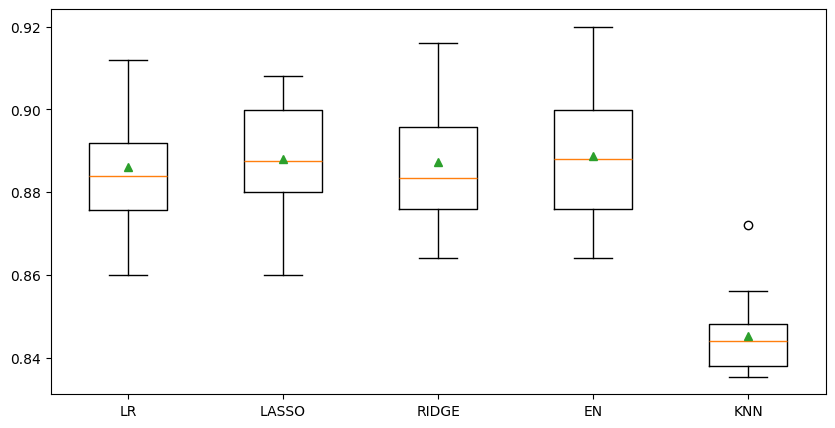

In [47]:
# 8a) Ajuste de hiperparámetros.
#     En cada modelo que utilcemos a continuación, utiliza la semilla "random_state=1"
#     indicada, para obtener la repetibilidad de los resultados en la manera de lo
#     posible. Es decir, este argumento y valor no deberás modificarlo.

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++


def mis_modelos():
  modelos, nombres = list(), list()

  # LR - Regresión Logística sin regularización:
  modelos.append(LogisticRegression(penalty=None,  # Este valor de "None" no lo debes cambiar. Define al modelo sin regularización.
                                    solver='lbfgs',
                                    max_iter=2000, # Incluye aquí todos los hiperparámetros y valores que consideres adecuados.
                                    random_state=1))
  nombres.append('LR')



  # Lasso - Regresión Logística con regularización L1:
  modelos.append(LogisticRegression(penalty='l1',
                                    C=1.0,
                                    solver='liblinear',
                                    max_iter=2000,# Incluye aquí todos los hiperparámetros y valores que consideres adecuados.
                                    random_state=1))
  nombres.append('LASSO')



  # Ridge - Regresión Logística con regularización L2:
  modelos.append(LogisticRegression(penalty='l2',
                                    C=1.0,
                                    solver='lbfgs',
                                    max_iter=2000,# Incluye aquí todos los hiperparámetros y valores que consideres adecuados.
                                    random_state=1))
  nombres.append('RIDGE')



  # Elastic_Net - - Regresión Logística con regularización L1 y L2:
  modelos.append(LogisticRegression(penalty='elasticnet',
                                    C=1.0,
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=2000,# Incluye aquí todos los hiperparámetros y valores que consideres adecuados.
                                    random_state=1))
  nombres.append('EN')



  # KNN - K-Vecinos más cercanos:
  modelos.append(KNeighborsClassifier(n_neighbors=5,
                                      weights='uniform',
                                      metric='minkowski',
                                      p=2,
                                      # Incluye aquí todos los hiperparámetros y valores que consideres adecuados.
                                      ))
  nombres.append('KNN')

  return modelos, nombres




# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# Pasamos al entrenamiento de los modelos.
# Hay obviamente varias maneras de llevar a cabo el entrenamiento,
# pero por el momento supongamos que lo hacemos de la manera siguiente:

modelos, nombres = mis_modelos()  # accesando los modelos.
resultados = list()    # para guardar los resultados en esta lista.

# Iterando y entrenando sobre cada modelo:
for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])   # Conjuntamos Transformaciones y modelos en un Pipeline.

  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)     # Aplicando una de las variantes de Validación Cruzada.

  scores = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring='accuracy', cv=cv1)   # Entrenando y generando los resultados con la exactitud (accuracy).


  resultados.append(scores)    # Guardamos los resultados en la lista.
  print('>> %s %.3f (%.3f)' % (nombres[i], np.nanmean(scores), np.nanstd(scores)))  # Desplegando los promedios de cada modelo.


plt.figure(figsize=(10,5))
plt.boxplot(resultados, tick_labels=nombres, showmeans=True)   # Gráficos de caja para una comparación visual de los resultados.
plt.show()


**8b) Comentarios sobre los resultados y modelos obtenidos. En particular indica cuál consideras el mejor modelo. ¿Alguno quedó subentrenado y ya no se pudo mejorar su desempeño?**

Con los resultados obtenidos, observamos desempeños similares, con valores accuracy entre 0.886 y 0.889. El modelo ElasticNet tuvo mejor desempeño.
Podemos decir que ningún modelo quedó sobreentrenado.


# **Ejercicio 9:**

* #### **Utiliza el mejor modelo encontrado en el paso anterior, los datos Xtv, ytv, y realiza ahora una búsqueda de malla con validación cruzada para tratar de mejorar el desempeño de este modelo.**

* #### **Sigue utilizando la métrica de la exactitud (accuracy).**

* #### **Verifica además que el modelo no esté subentrenado o sobreentrenado.**

* #### **Llama "resultado_malla" al mejor modelo ajustado.**




* **NOTA-1: Para esta actividad diremos que el modelo no está sobreentrenado si la diferencia entre Train y Validation es menor al 3%.**


* **NOTA-2: Puedes utilizar GridSearchCV, o bien, RandomizedSearchCV. La documentación la puedes consultar en las siguientes ligas:**

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html


In [50]:
# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++

modelo_EN = LogisticRegression(penalty='elasticnet',
                                    solver='saga',
                                    max_iter=2000,
                                    random_state=1)

pipeline_EN = Pipeline(steps=[('ct',columnasTransformer),('m',modelo_EN)])

param_grid = {
    'm__C': [0.001, 0.01, 0.1, 1, 10],
    'm__l1_ratio': [0.25, 0.5, 0.75]
}

cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)


resultado_malla = GridSearchCV(
    estimator=pipeline_EN,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv1,
    return_train_score=True,
    n_jobs=-1
)

resultado_malla.fit(Xtv, np.ravel(ytv))


# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


print("Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)")
print("-"*65)
print("Mejor modelo: %f usando los hiperparámetros %s" % (resultado_malla.best_score_, resultado_malla.best_params_))
print('Promedios Train mean(std): %.2f%% (%.4f%%)' % (100*np.nanmean(resultado_malla.cv_results_['mean_train_score']),
                                                 100*np.nanmean(resultado_malla.cv_results_['std_train_score'])))
print('Promedios Val mean(std): %.2f%% (%.4f%%)' % (100*resultado_malla.cv_results_['mean_test_score'].mean(),
                                               100*resultado_malla.cv_results_['std_test_score'].mean()))


Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)
-----------------------------------------------------------------
Mejor modelo: 0.888709 usando los hiperparámetros {'m__C': 1, 'm__l1_ratio': 0.5}
Promedios Train mean(std): 87.57% (0.2886%)
Promedios Val mean(std): 86.63% (0.8788%)


# **Ejercicio 10:**

#### **Finalmente, usando el conjunto de prueba (Test) responde los siguientes incisos:**

#### **a) Obtener el desempeño final del mejor modelo con el reporte de métricas classification_report() de Sklearn.**

#### **b) Obtener la matriz de confusión del mejor modelo.**

#### **c) Indica como se leen o interpretan los valores VP, VN, FP, FN obtenidos y de acuerdo al contexto del problema.**

#### **d) Realiza un análisis de importancia de los factores o características e incluye tus comentarios.**



In [51]:
# a) Reporte del desempeño con classification_report():

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++


ypred = resultado_malla.predict(Xtest)



print(classification_report(ytestT, ypred,
                            target_names=['No','Yes']))

# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


              precision    recall  f1-score   support

          No       0.89      0.96      0.92       185
         Yes       0.67      0.39      0.49        36

    accuracy                           0.87       221
   macro avg       0.78      0.68      0.71       221
weighted avg       0.85      0.87      0.85       221



Podemos visualizar resultados interesantes.
Aunque el modelo tiene una exectitud de 87%, para la clase "no" presentó un buen desempeño pero para la clase "yes" el desempeño es menor. Se tiene un recal de 0.39 y f1-score de 0.49. El modelo no está identificando correctamente o con exactitud a los empleados que tienen attrition.

In [53]:
# b) Matriz de confusión:

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++


from sklearn.metrics import confusion_matrix
matriz_confusion = confusion_matrix(ytestT, ypred)

print(matriz_confusion)


# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


[[178   7]
 [ 22  14]]


*  c) Interpretación de VP, VF, FP, FN.
#### +++++++++ Inicia sección para incluir tus comentarios ++++++++++++++++++++++++

None


* **VP:** 14 | El emplreado es attrition y el modelo predijo que es attrition.

* **VN:** 178 | El empleado no es attrition y el modelo predijo que no es attrition.

* **FP:** 7 | El empleado no es attrition y el modelo predijo que es attrition.

* **FN:** 22 | El empleado es attrition y el modelo predijo que no es attrition. --> Consideo que este es el punto más importante. De los 36 attrition el modelo no predijo correctamente a 22.

#### +++++++++ Termina sección para incluir tus comentarios ++++++++++++++++++++++++

In [54]:
# 10d) Inportancia de factores

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++


mejor_modelo = resultado_malla.best_estimator_
nombres_variables = mejor_modelo.named_steps['ct'].get_feature_names_out()
coeficientes = mejor_modelo.named_steps['m'].coef_[0]

importancia = pd.DataFrame({'Variable': nombres_variables, 'Coeficiente': coeficientes})
importancia['importancia'] = importancia['Coeficiente'].abs()
importancia = importancia.sort_values(by='importancia', ascending=False)

print(importancia.head(10))


# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++



                                       Variable  Coeficiente  importancia
24                           binarias__OverTime     2.085647     2.085647
25  nominales__BusinessTravel_Travel_Frequently     1.648992     1.648992
43              nominales__MaritalStatus_Single     0.993763     0.993763
35     nominales__JobRole_Laboratory Technician     0.668901     0.668901
16                    ordinales__JobInvolvement    -0.647531     0.647531
26      nominales__BusinessTravel_Travel_Rarely     0.614134     0.614134
33   nominales__EducationField_Technical Degree     0.572825     0.572825
6                      numericas__MonthlyIncome    -0.563901     0.563901
10                    numericas__YearsAtCompany     0.535466     0.535466
38         nominales__JobRole_Research Director    -0.514012     0.514012


*  **10d) Comentarios sobre los resultados sobre el análisis de importancia de factores o características**

Podemos observar que la variable "OverTime" es la variable que tiene mayor peso en el modelo, con un coeficiente de 2.08. Seguida de "BusinessTravelFrequently". Podemos decir que trabajr mayor número de horas y tener una frecuencia alta de viajes puede estas asociado con una mayor probabilidad de attrition.

Por otro lado podemos ver variables como "JonInvolment" y "MonthlyIncome" que podrían estar relacionadas con una menor probabilidad de attrition.

# **Ejercicio 11:**


### **Para terminar, responde las siguientes preguntas relacionadas con las implicaciones involucradas con la toma de decisiones basadas en los resultados de un modelo de aprendizaje automático. El objetivo es reflexionar sobre estas implicaciones y no dudes en compartir tus experiencias en caso de que te hayas enfrentado a una situación similar en tu trabajo.**

* **a) Si tu modelo predice e identifica con un alto porcentaje de exactitud quiénes de los colaboradores de la empresa estarán abandonando su puesto muy pronto, ¿cómo debería usarse esa información? Al responder, considera que es importante cuidar la parte ética y de privacidad de la información del colaborador.**

* **b) Con base a los resultados de la matriz de confusión, ¿qué tipo de error (FN o FP) está considerando como más costoso el modelo? En particular, ¿coincide con la respuesta que diste en el Ejercicio 6e?**

* **c) ¿Cómo comunicarías los resultados del modelo obtenido en esta actividad a un público no técnico, es decir, sin los conocimientos de temas de aprendizaje automático. Por ejemplo, supongamos que vas a comunicarle tus resultados a los directivos de la empresa o al personal del área de Recursos Humanos.**

* **d) ¿En cuáles ejercicios anteriores consideras que el (o los) modelo de lenguaje de gran tamaño LLM utilizado fue de mayor ayuda? ¿Por qué?**

* **e) Incluye tus conclusiones finales de la actividad.**

---

#### +++++++++ Inicia sección para incluir tus conclusiones ++++++++++++++++++++++++


* a) Me parece importante usar esta información para retener al talento. Muchas veces los empleados no se van porque no les guste su trabajo sino porque, como vimos en el ejercicio anterior, hay una carga de trabajo pesada que puede influir en el estilo y bienestar de vida. Así como los viajes frecuentes que pueden impedir una estabilidad en la vida personal. Me parece que lo importante debería ser buscar regular esos factores para que los empleados no decidan irse. Siempre tomando encuenta a legal y RH para no involucrar malas prácticas éticas.

* b) Sí coincide. Considero que el error FN es el más costoso porque no se está prediciendo correctamente cuando un empleado es attrititon por lo que no se pueden tomar las medidas de retención de talento.

* c) Comunicaría que existen factores específicos que están relacionados con la decisión de un empleado de irse de la empresa. Tenemos factores como las horas laboradas y los viajes con frecuencia. El objetivo es decir: mientras más horas trabaja un empleado y mayor frecuencia de viajes tiene, mayor es la posibilidad de que se vaya de la empresa. ¿Cómo logramos un balance de horas y viajes para retener al talento?

* d) En el 8 y 9 porque se me dificultó bastante entender los conceptos. tuve que estar investigando, preguntando y entendiendo todos los valores para los hiperparámetros. La teoría es entendible así como el objetivo pero para programar me representaron retos importantes al no conocer por completo las funciones.

* e) Respecto a los resultados me parece extremadamente emocionante e importante cómo los modelos nos pueden ayudar a mejorar la toma de decisiones. ¿cómo como compañía podemos voltear a ver el impacto de varios factores en la vida de un empleado? ¿cómo como compañía entiendes que tienes errores que necesitas remediar para evitar la fuga de talento?

Como actividad de la maestría me pareció muy retadora, me tardé muchísimas horas para lograr terminar la actividad. Aunque me pareció un ejercicio bastante bueno para entender un modelo completo.

#### +++++++++ Termina sección para incluir tus conclusiones ++++++++++++++++++++++++

# >> **Fin de la Actividad de Rotación de Personal de la Semana 3** <<